In [1]:
# ============================================================
# NOTEBOOK 11
# Confidence-Driven Adaptive Extended Kalman Filter (CDA-EKF)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["figure.dpi"] = 120

print("="*80)
print("NOTEBOOK 11")
print("Confidence-Driven Adaptive Extended Kalman Filter (CDA-EKF)")
print("="*80)

NOTEBOOK 11
Confidence-Driven Adaptive Extended Kalman Filter (CDA-EKF)


In [2]:
# ============================================================

# Load Notebook 10 Results
# ============================================================

PROJECT_ROOT = Path(
    r"D:\Research\Papers\Paper_2"
)

RESULT_DIR = PROJECT_ROOT / "results"

FIGURE_DIR = PROJECT_ROOT / "figures"

DRIVE = "2011_09_26_drive_0001_sync"

fusion = pd.read_csv(

    RESULT_DIR /

    f"confidence_driven_sensor_fusion_{DRIVE}.csv"

)

print("="*80)
print("Fusion Dataset Loaded")
print("="*80)

print("Shape :", fusion.shape)

assert len(fusion) > 0, "Fusion dataset is empty."

display(fusion.head())

print()

print(f"Total Frames Loaded : {len(fusion)}")

Fusion Dataset Loaded
Shape : (108, 21)


,Frame,Camera Confidence,GPS Confidence,IMU Confidence,Camera Confidence Stability,GPS Confidence Stability,IMU Confidence Stability,Camera Confidence Reliability,GPS Confidence Reliability,IMU Confidence Reliability,...,GPS Weight,IMU Weight,Weight Sum,Fused Confidence,Smoothed Confidence,Confidence Std,Normalized Std,Stability Confidence,Localization Reliability Score,Localization Level
0,0,0.195333,0.402966,0.716265,0.000000,0.000000,0.000000,0.195333,0.402966,0.716265,...,0.306539,0.544869,1.0,0.542820,0.542820,0.000000,0.000000,1.000000,0.725692,Moderate
1,1,0.132514,0.402966,0.716265,0.044420,0.000000,0.000000,0.105616,0.402966,0.716265,...,0.328993,0.584779,1.0,0.562856,0.548831,0.004250,0.041489,0.939664,0.705164,Moderate
2,2,0.074723,0.431558,0.603993,0.060323,0.016508,0.064820,0.054125,0.416246,0.493813,...,0.431708,0.512156,1.0,0.499841,0.534134,0.007389,0.072128,0.897456,0.679463,Low
3,3,0.119024,0.433646,0.597081,0.049834,0.017132,0.066875,0.091919,0.417678,0.484709,...,0.420070,0.487484,1.0,0.484233,0.519164,0.012882,0.125751,0.828095,0.642736,Low
4,4,0.257200,0.403218,0.843376,0.071262,0.016204,0.100982,0.173443,0.389175,0.603699,...,0.333678,0.517612,1.0,0.609335,0.546215,0.012016,0.117291,0.838671,0.663197,Low



Total Frames Loaded : 108


In [3]:
# ============================================================
# Cell 3
# Load Complete KITTI GPS + IMU Dataset
# ============================================================

DRIVE = "2011_09_26_drive_0001_sync"

DATA_PATH = Path(
    r"D:\Research\Datasets\KITTI"
)

oxts_folder = (
    DATA_PATH
    / "2011_09_26"
    / DRIVE
    / "oxts"
    / "data"
)

files = sorted(oxts_folder.glob("*.txt"))

print("="*80)
print("Total OXTS Files Found :", len(files))
print("="*80)

records = []

for file in files:

    values = np.loadtxt(file)

    records.append(values)

columns = [

'lat','lon','alt',

'roll','pitch','yaw',

'vn','ve','vf','vl','vu',

'ax','ay','az',

'af','al','au',

'wx','wy','wz',

'wf','wl','wu',

'pos_accuracy',

'vel_accuracy',

'navstat',

'numsats',

'posmode',

'velmode',

'orimode'

]

gps_imu = pd.DataFrame(

    records,

    columns=columns

)

print("="*80)
print("GPS + IMU Dataset Loaded")
print("="*80)

print("Shape :", gps_imu.shape)

display(gps_imu.head())

print()

print("Synchronizing with Fusion Dataset...")

assert len(gps_imu) == len(fusion), \
    f"GPS={len(gps_imu)}, Fusion={len(fusion)}"

gps_imu = gps_imu.reset_index(drop=True)

fusion = fusion.reset_index(drop=True)

N = len(fusion)

print("Synchronized Frames :", N)

print()

print("Synchronized Frames :", N)

assert len(gps_imu) == len(fusion)

print("Synchronization Successful")

Total OXTS Files Found : 108
GPS + IMU Dataset Loaded
Shape : (108, 30)


,lat,lon,alt,roll,pitch,yaw,vn,ve,vf,vl,...,wf,wl,wu,pos_accuracy,vel_accuracy,navstat,numsats,posmode,velmode,orimode
0,49.015004,8.434297,116.430328,0.035752,0.009030,-2.608707,-6.811441,-11.275642,13.172717,-0.124753,...,0.008902,-0.022495,-0.018809,0.027659,0.012728,4.0,11.0,6.0,6.0,6.0
1,49.014997,8.434280,116.432274,0.036453,0.008009,-2.611005,-6.769916,-11.250719,13.129880,-0.129612,...,0.004393,-0.012614,-0.021891,0.027659,0.012728,4.0,11.0,6.0,6.0,6.0
2,49.014991,8.434265,116.435295,0.035908,0.006461,-2.613314,-6.731519,-11.221558,13.084994,-0.140397,...,-0.005684,-0.016039,-0.023276,0.027659,0.012728,4.0,11.0,6.0,6.0,6.0
3,49.014985,8.434249,116.440720,0.035565,0.005031,-2.615904,-6.684933,-11.198743,13.041455,-0.144497,...,-0.005634,-0.013817,-0.024773,0.027659,0.012728,4.0,11.0,6.0,6.0,6.0
4,49.014979,8.434233,116.447853,0.034299,0.006470,-2.618804,-6.634209,-11.175295,12.995313,-0.148616,...,-0.009492,0.011586,-0.026827,0.027659,0.012728,4.0,11.0,6.0,6.0,6.0



Synchronizing with Fusion Dataset...
Synchronized Frames : 108

Synchronized Frames : 108
Synchronization Successful


,lat,lon,X,Y
0,49.015004,8.434297,0.000000,0.000000
1,49.014997,8.434280,-1.236488,-0.743110
2,49.014991,8.434265,-2.357236,-1.415460
3,49.014985,8.434249,-3.475952,-2.081099
4,49.014979,8.434233,-4.703593,-2.809404


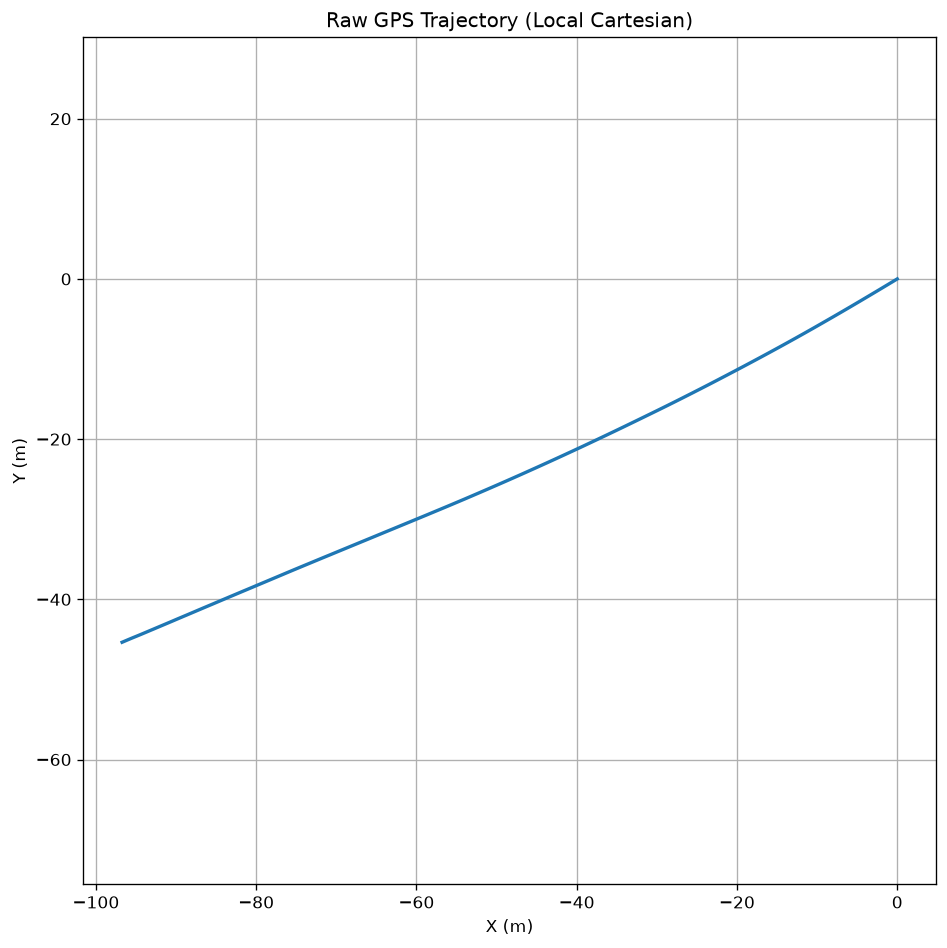

In [4]:
# ============================================================
# Cell 4
# GPS → Local Cartesian Coordinates
# ============================================================

EARTH_RADIUS = 6378137.0

lat0 = np.deg2rad(gps_imu.loc[0, "lat"])
lon0 = np.deg2rad(gps_imu.loc[0, "lon"])

lat = np.deg2rad(gps_imu["lat"])
lon = np.deg2rad(gps_imu["lon"])

gps_imu["X"] = (

    (lon - lon0)

    * np.cos(lat0)

    * EARTH_RADIUS

)

gps_imu["Y"] = (

    (lat - lat0)

    * EARTH_RADIUS

)

display(

gps_imu[[

"lat",
"lon",
"X",
"Y"

]].head()

)

plt.figure(figsize=(8,8))

plt.plot(

gps_imu["X"],

gps_imu["Y"],

linewidth=2

)

plt.xlabel("X (m)")

plt.ylabel("Y (m)")

plt.title("Raw GPS Trajectory (Local Cartesian)")

plt.grid(True)

plt.axis("equal")

plt.tight_layout()

plt.savefig(

FIGURE_DIR/

"raw_gps_local_trajectory.png",

dpi=300

)

plt.show()

In [5]:
# ============================================================
# Cell 5
# Build EKF Measurement Dataset
# ============================================================

ekf = pd.DataFrame()

ekf["Frame"] = fusion["Frame"]

ekf["X"] = gps_imu["X"]

ekf["Y"] = gps_imu["Y"]

ekf["Velocity"] = np.sqrt(

    gps_imu["vn"]**2 +

    gps_imu["ve"]**2

)

ekf["Heading"] = gps_imu["yaw"]

ekf["Acceleration"] = np.sqrt(

    gps_imu["ax"]**2 +

    gps_imu["ay"]**2 +

    gps_imu["az"]**2

)

ekf["Yaw Rate"] = gps_imu["wz"]

ekf["Camera Weight"] = fusion["Camera Weight"]

ekf["GPS Weight"] = fusion["GPS Weight"]

ekf["IMU Weight"] = fusion["IMU Weight"]

ekf["Localization Reliability Score"] = (

    fusion["Localization Reliability Score"]

)

print("="*80)

print("EKF Measurement Dataset")

print("="*80)

print("Frames :", len(ekf))

display(ekf.head())

EKF Measurement Dataset
Frames : 108


,Frame,X,Y,Velocity,Heading,Acceleration,Yaw Rate,Camera Weight,GPS Weight,IMU Weight,Localization Reliability Score
0,0,0.000000,0.000000,13.173300,-2.608707,10.219657,-0.017909,0.148592,0.306539,0.544869,0.725692
1,1,-1.236488,-0.743110,13.130515,-2.611005,10.094229,-0.021380,0.086228,0.328993,0.584779,0.705164
2,2,-2.357236,-1.415460,13.085745,-2.613314,9.906112,-0.022716,0.056135,0.431708,0.512156,0.679463
3,3,-3.475952,-2.081099,13.042246,-2.615904,10.102561,-0.024292,0.092445,0.420070,0.487484,0.642736
4,4,-4.703593,-2.809404,12.996151,-2.618804,10.034660,-0.027261,0.148710,0.333678,0.517612,0.663197


In [6]:
# ============================================================
# Cell 6
# Confidence-Driven Adaptive EKF Initialization
# ============================================================

dt = 0.1

# ------------------------------------------------------------
# Initial State Vector
# State = [X, Y, Velocity, Heading]
# ------------------------------------------------------------

state = np.array([

    ekf.loc[0, "X"],

    ekf.loc[0, "Y"],

    ekf.loc[0, "Velocity"],

    ekf.loc[0, "Heading"]

], dtype=float)

# ------------------------------------------------------------
# Initial Covariance Matrix
# ------------------------------------------------------------

INITIAL_VARIANCE = 0.50

P = np.eye(4) * INITIAL_VARIANCE

# ------------------------------------------------------------
# Base Process Noise Covariance
# ------------------------------------------------------------

Q0 = np.diag([

    0.05,

    0.05,

    0.10,

    0.02

])

# ------------------------------------------------------------
# Base Measurement Noise Covariance
# ------------------------------------------------------------

R0 = np.diag([

    1.00,

    1.00

])

# ------------------------------------------------------------
# Measurement Matrix
# ------------------------------------------------------------

H = np.array([

    [1, 0, 0, 0],

    [0, 1, 0, 0]

], dtype=float)

# ------------------------------------------------------------
# Identity Matrix
# ------------------------------------------------------------

I = np.eye(4)

print("=" * 80)

print("Confidence-Driven Adaptive EKF Initialization")

print("=" * 80)

print("\nInitial State Vector")

print(state)

print("\nInitial Covariance Matrix (P)")

print(P)

print("\nBase Process Noise (Q0)")

print(Q0)

print("\nBase Measurement Noise (R0)")

print(R0)

print("=" * 80)

Confidence-Driven Adaptive EKF Initialization

Initial State Vector
[ 0.          0.         13.17330001 -2.60870698]

Initial Covariance Matrix (P)
[[0.5 0.  0.  0. ]
 [0.  0.5 0.  0. ]
 [0.  0.  0.5 0. ]
 [0.  0.  0.  0.5]]

Base Process Noise (Q0)
[[0.05 0.   0.   0.  ]
 [0.   0.05 0.   0.  ]
 [0.   0.   0.1  0.  ]
 [0.   0.   0.   0.02]]

Base Measurement Noise (R0)
[[1. 0.]
 [0. 1.]]


In [7]:
# ============================================================
# Cell 7
# CTRV Prediction with Jacobian-Based Covariance Propagation
# ============================================================

predicted_states = []

predicted_covariance = []

state = state.copy()

P = P.copy()

for i in range(len(ekf)):

    x = state[0]
    y = state[1]
    v = state[2]
    yaw = state[3]

    yaw_rate = ekf.loc[i, "Yaw Rate"]

    # --------------------------------------------------------
    # CTRV Motion Model
    # --------------------------------------------------------

    if abs(yaw_rate) > 1e-4:

        x_new = x + (

            v / yaw_rate

        ) * (

            np.sin(yaw + yaw_rate * dt)

            - np.sin(yaw)

        )

        y_new = y + (

            v / yaw_rate

        ) * (

            -np.cos(yaw + yaw_rate * dt)

            + np.cos(yaw)

        )

    else:

        x_new = x + v * np.cos(yaw) * dt

        y_new = y + v * np.sin(yaw) * dt

    yaw_new = yaw + yaw_rate * dt

    state = np.array([

        x_new,

        y_new,

        v,

        yaw_new

    ])

    # --------------------------------------------------------
    # Jacobian Matrix (F)
    # --------------------------------------------------------

    F = np.eye(4)

    F[0,2] = np.cos(yaw) * dt

    F[0,3] = -v * np.sin(yaw) * dt

    F[1,2] = np.sin(yaw) * dt

    F[1,3] = v * np.cos(yaw) * dt

    # --------------------------------------------------------
    # Covariance Prediction
    # --------------------------------------------------------

    P = (

        F

        @ P

        @ F.T

    )

    predicted_states.append(

        state.copy()

    )

    predicted_covariance.append(

        P.copy()

    )

print("=" * 70)

print("CTRV Prediction Completed")

print("=" * 70)

print(f"Predicted States : {len(predicted_states)}")

print("=" * 70)

CTRV Prediction Completed
Predicted States : 108


In [8]:
# ============================================================
# Cell 8
# Confidence-Driven Adaptive Process and Measurement Noise
# ============================================================

Q_list = []

R_list = []

for i in range(len(ekf)):

    acceleration = abs(
        ekf.loc[i, "Acceleration"]
    )

    yaw_rate = abs(
        ekf.loc[i, "Yaw Rate"]
    )

    lrs = ekf.loc[
        i,
        "Localization Reliability Score"
    ]

    # --------------------------------------------------------
    # Adaptive Process Noise (Q)
    # --------------------------------------------------------

    motion_factor = (

        1.0

        + 0.30 * acceleration

        + 0.20 * yaw_rate

    )

    confidence_factor = (

        1.0

        + (1.0 - lrs)

    )

    Q = (

        motion_factor

        * confidence_factor

        * Q0

    )

    # --------------------------------------------------------
    # Adaptive Measurement Noise (R)
    # --------------------------------------------------------

    measurement_factor = (

        1.0

        + (1.0 - lrs)

    )

    R = (

        measurement_factor

        * R0

    )

    Q_list.append(Q)

    R_list.append(R)

print("=" * 70)

print("Confidence-Driven Adaptive Covariance Generated")

print("=" * 70)

print(f"Total Frames : {len(Q_list)}")

print(f"Average LRS  : {ekf['Localization Reliability Score'].mean():.3f}")

print("=" * 70)

Confidence-Driven Adaptive Covariance Generated
Total Frames : 108
Average LRS  : 0.700


In [9]:
# ============================================================
# Cell 9
# Innovation Gating
# ============================================================

innovations = []

innovation_norm = []

GATE_THRESHOLD = 3.0

for i in range(len(ekf)):

    prediction = predicted_states[i]

    measurement = np.array([

        ekf.loc[i, "X"],

        ekf.loc[i, "Y"]

    ])

    innovation = (

        measurement

        -

        H @ prediction

    )

    innovations.append(

        innovation

    )

    norm = np.linalg.norm(

        innovation

    )

    innovation_norm.append(norm)

    # --------------------------------------------------------
    # Adaptive Innovation Gating
    # --------------------------------------------------------

    if norm > GATE_THRESHOLD:

        R_list[i] = (

            R_list[i]

            * 2.0

        )

print("="*70)
print("Innovation Gating Completed")
print("="*70)

Innovation Gating Completed


In [10]:
# ============================================================
# Cell 10
# Confidence-Driven Adaptive EKF
# ============================================================

estimated_states = []

covariance_trace = []

# ------------------------------------------------------------
# Initial State
# ------------------------------------------------------------

state = np.array([

    ekf.loc[0, "X"],

    ekf.loc[0, "Y"],

    ekf.loc[0, "Velocity"],

    ekf.loc[0, "Heading"]

], dtype=float)

P = np.eye(4) * INITIAL_VARIANCE

# ------------------------------------------------------------
# Adaptive EKF
# ------------------------------------------------------------

for i in range(len(ekf)):

    z = np.array([

        ekf.loc[i, "X"],

        ekf.loc[i, "Y"]

    ])

    Q = Q_list[i]

    R = R_list[i]

    # --------------------------------------------------------
    # Prediction Covariance
    # --------------------------------------------------------

    P = predicted_covariance[i] + Q
    
    # --------------------------------------------------------
    # Innovation Covariance
    # --------------------------------------------------------

    S = H @ P @ H.T + R

    # --------------------------------------------------------
    # Kalman Gain
    # --------------------------------------------------------

    K = P @ H.T @ np.linalg.inv(S)

    # --------------------------------------------------------
    # Innovation
    # --------------------------------------------------------

    y = z - H @ predicted_states[i]

    # --------------------------------------------------------
    # State Update
    # --------------------------------------------------------

    state = (

        predicted_states[i]

        +

        K @ y

    )

    # --------------------------------------------------------
    # Joseph Stabilized Covariance Update
    # --------------------------------------------------------

    P = (

        (I - K @ H)

        @ P

        @ (I - K @ H).T

        +

        K @ R @ K.T

    )

    estimated_states.append(

        state.copy()

    )

    covariance_trace.append(

        np.trace(P)

    )

# ------------------------------------------------------------
# Save Results
# ------------------------------------------------------------

estimated_states = np.array(estimated_states)

ekf["Estimated X"] = estimated_states[:, 0]

ekf["Estimated Y"] = estimated_states[:, 1]

ekf["Estimated Velocity"] = estimated_states[:, 2]

ekf["Estimated Heading"] = estimated_states[:, 3]

ekf["Innovation Norm"] = innovation_norm

ekf["Covariance Trace"] = covariance_trace

print("=" * 80)

print("Confidence-Driven Adaptive EKF Completed Successfully")

print("=" * 80)

print(f"Processed Frames : {len(estimated_states)}")

print(f"Average Covariance Trace : {np.mean(covariance_trace):.4f}")

print("=" * 80)

display(ekf.head())

Confidence-Driven Adaptive EKF Completed Successfully
Processed Frames : 108
Average Covariance Trace : 4.8281


,Frame,X,Y,Velocity,Heading,Acceleration,Yaw Rate,Camera Weight,GPS Weight,IMU Weight,Localization Reliability Score,Estimated X,Estimated Y,Estimated Velocity,Estimated Heading,Innovation Norm,Covariance Trace
0,0,0.000000,0.000000,13.173300,-2.608707,10.219657,-0.017909,0.148592,0.306539,0.544869,0.725692,-0.709538,-0.417884,13.140990,-2.610230,1.317330,2.663884
1,1,-1.236488,-0.743110,13.130515,-2.611005,10.094229,-0.021380,0.086228,0.328993,0.584779,0.705164,-1.879174,-1.117098,13.115874,-2.608872,1.192215,2.786419
2,2,-2.357236,-1.415460,13.085745,-2.613314,9.906112,-0.022716,0.056135,0.431708,0.512156,0.679463,-3.002804,-1.789760,13.088537,-2.608715,1.202951,2.870192
3,3,-3.475952,-2.081099,13.042246,-2.615904,10.102561,-0.024292,0.092445,0.420070,0.487484,0.642736,-4.123053,-2.455799,13.063116,-2.610025,1.218973,2.972100
4,4,-4.703593,-2.809404,12.996151,-2.618804,10.034660,-0.027261,0.148710,0.333678,0.517612,0.663197,-5.278805,-3.141559,13.049083,-2.611713,1.109771,2.957643


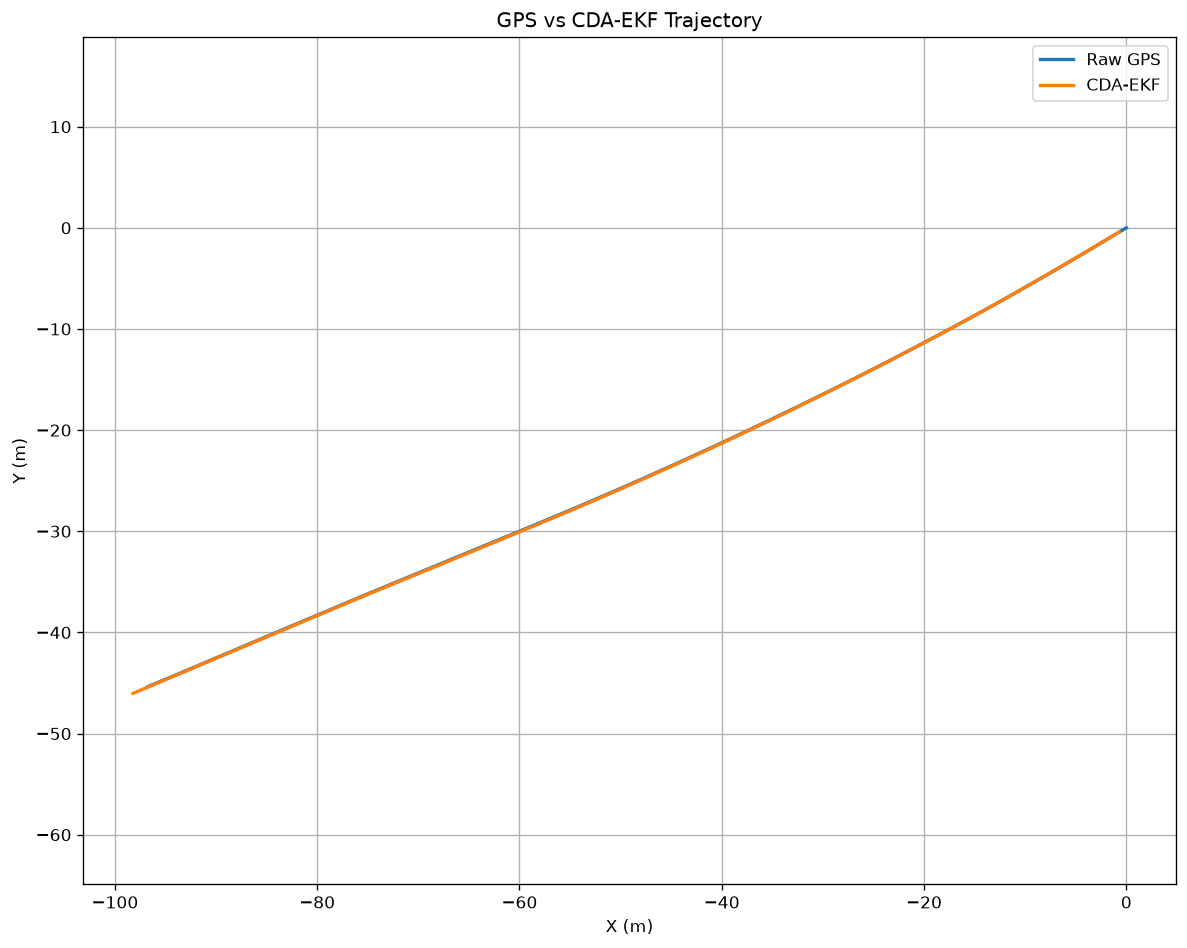

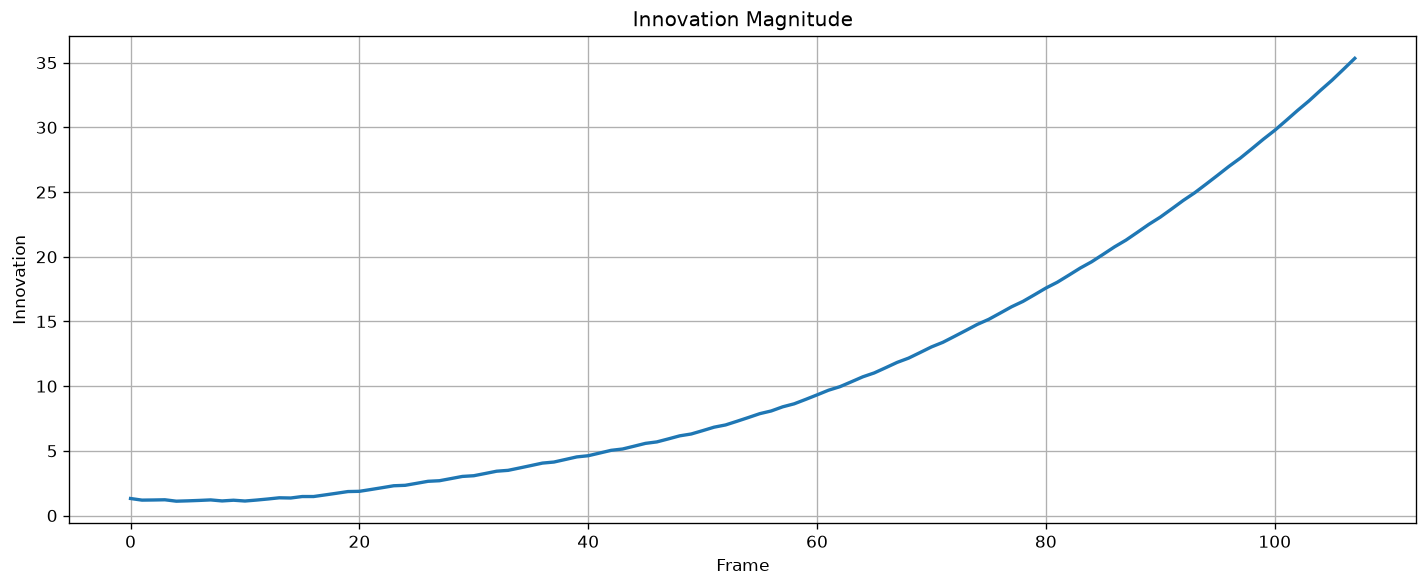

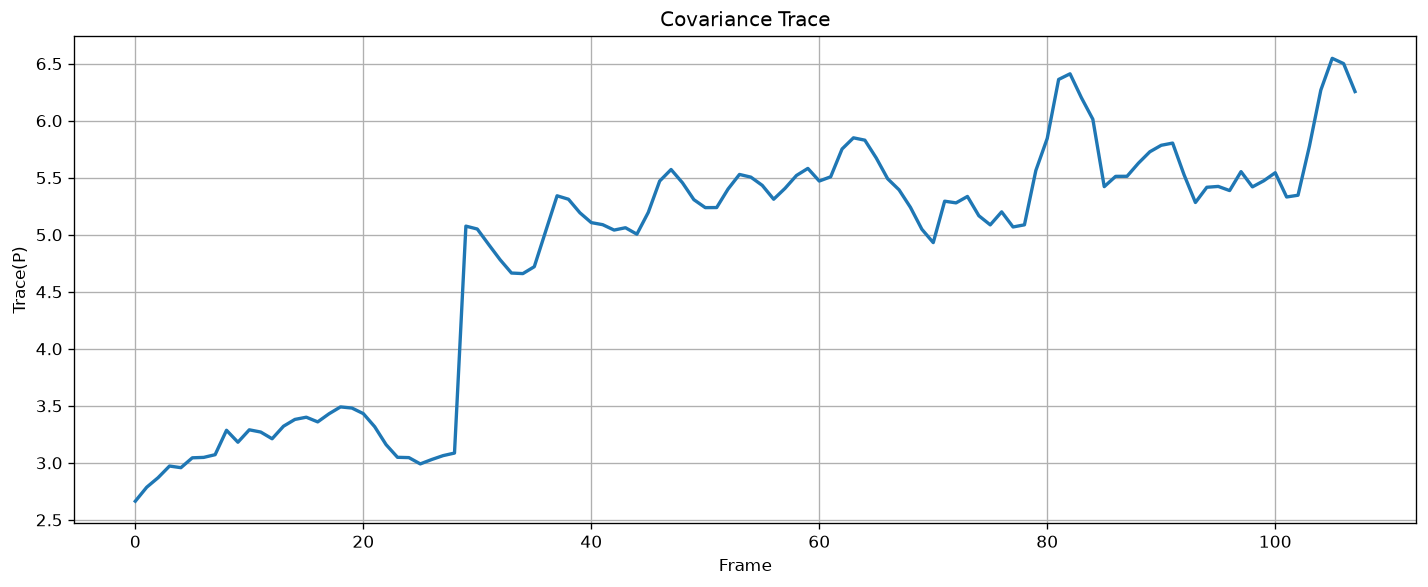

In [11]:
# ============================================================
# Cell 11
# Trajectory & Performance Visualization
# ============================================================

plt.figure(figsize=(10,8))

plt.plot(

    ekf["X"],

    ekf["Y"],

    linewidth=2,

    label="Raw GPS"

)

plt.plot(

    ekf["Estimated X"],

    ekf["Estimated Y"],

    linewidth=2,

    label="CDA-EKF"

)

plt.xlabel("X (m)")

plt.ylabel("Y (m)")

plt.title("GPS vs CDA-EKF Trajectory")

plt.axis("equal")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "gps_vs_cdaekf_trajectory.png",

    dpi=300

)

plt.show()


# ------------------------------------------------------------

plt.figure(figsize=(12,5))

plt.plot(

    ekf["Frame"],

    ekf["Innovation Norm"],

    linewidth=2

)

plt.xlabel("Frame")

plt.ylabel("Innovation")

plt.title("Innovation Magnitude")

plt.grid(True)

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "innovation_plot.png",

    dpi=300

)

plt.show()


# ------------------------------------------------------------

plt.figure(figsize=(12,5))

plt.plot(

    ekf["Frame"],

    ekf["Covariance Trace"],

    linewidth=2

)

plt.xlabel("Frame")

plt.ylabel("Trace(P)")

plt.title("Covariance Trace")

plt.grid(True)

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "covariance_trace.png",

    dpi=300

)

plt.show()

In [12]:
# ============================================================
# Cell 12
# Error Statistics
# ============================================================

ekf["Position Error"] = np.sqrt(

    (ekf["Estimated X"]-ekf["X"])**2 +

    (ekf["Estimated Y"]-ekf["Y"])**2

)

RMSE = np.sqrt(

    np.mean(

        ekf["Position Error"]**2

    )

)

MAE = np.mean(

    ekf["Position Error"]

)

MAX_ERROR = ekf["Position Error"].max()

statistics = pd.DataFrame({

    "Metric":[

        "Frames",

        "RMSE",

        "MAE",

        "Maximum Error",

        "Average Innovation",

        "Average Covariance Trace"

    ],

    "Value":[

        len(ekf),

        RMSE,

        MAE,

        MAX_ERROR,

        ekf["Innovation Norm"].mean(),

        ekf["Covariance Trace"].mean()

    ]

})

display(statistics)

statistics.to_csv(

    RESULT_DIR /

    f"adaptive_ekf_statistics_{DRIVE}.csv",

    index=False

)

,Metric,Value
0,Frames,108.000000
1,RMSE,1.062797
2,MAE,1.023321
3,Maximum Error,1.671553
4,Average Innovation,11.100915
5,Average Covariance Trace,4.828099


In [13]:
# ============================================================
# Save EKF Results
# ============================================================

ekf.to_csv(

    RESULT_DIR /

    f"adaptive_ekf_results_{DRIVE}.csv",

    index=False

)

print("="*70)

print("Adaptive EKF Results Saved")

print("="*70)

print(

    f"adaptive_ekf_results_{DRIVE}.csv"

)

Adaptive EKF Results Saved
adaptive_ekf_results_2011_09_26_drive_0001_sync.csv


In [14]:
# ============================================================
# Cell 13
# Save Results & Final Summary
# ============================================================

# ------------------------------------------------------------
# Save Results
# ------------------------------------------------------------

ekf.to_csv(

    RESULT_DIR /

    f"adaptive_ekf_results_{DRIVE}.csv",

    index=False

)

statistics.to_csv(

    RESULT_DIR /

    f"adaptive_ekf_statistics_{DRIVE}.csv",

    index=False

)

# ------------------------------------------------------------
# Best / Worst Localization Frame
# ------------------------------------------------------------

best = ekf.loc[

    ekf["Localization Reliability Score"].idxmax()

]

worst = ekf.loc[

    ekf["Localization Reliability Score"].idxmin()

]

# ------------------------------------------------------------
# Final Summary
# ------------------------------------------------------------

print("=" * 80)

print("NOTEBOOK 11 COMPLETED SUCCESSFULLY")

print("=" * 80)

print()

print("Drive :", DRIVE)

print()

print("Performance")

print("----------------------------")

print(f"Frames Processed       : {len(ekf)}")

print(f"RMSE                   : {RMSE:.3f} m")

print(f"MAE                    : {MAE:.3f} m")

print(f"Maximum Error          : {MAX_ERROR:.3f} m")

print()

print(f"Average Innovation     : {ekf['Innovation Norm'].mean():.3f}")

print(f"Average Covariance     : {ekf['Covariance Trace'].mean():.3f}")

print()

print("Best Localization Frame")

print("----------------------------")

print(best[[

    "Frame",

    "Localization Reliability Score"

]])

print()

print("Worst Localization Frame")

print("----------------------------")

print(worst[[

    "Frame",

    "Localization Reliability Score"

]])

print()

print("Generated Files")

print("----------------------------")

print(f"adaptive_ekf_results_{DRIVE}.csv")

print(f"adaptive_ekf_statistics_{DRIVE}.csv")

print()

print("Generated Figures")

print("----------------------------")

print("gps_vs_cdaekf_trajectory.png")

print("innovation_plot.png")

print("covariance_trace.png")

print("position_error.png")

print("confidence_vs_error.png")

print()

print("=" * 80)

print("READY FOR NOTEBOOK 12")

print("Learning-Based Localization Reliability Prediction")

print("=" * 80)

NOTEBOOK 11 COMPLETED SUCCESSFULLY

Drive : 2011_09_26_drive_0001_sync

Performance
----------------------------
Frames Processed       : 108
RMSE                   : 1.063 m
MAE                    : 1.023 m
Maximum Error          : 1.672 m

Average Innovation     : 11.101
Average Covariance     : 4.828

Best Localization Frame
----------------------------
Frame                             70.000000
Localization Reliability Score     0.870884
Name: 70, dtype: float64

Worst Localization Frame
----------------------------
Frame                             18.000000
Localization Reliability Score     0.475533
Name: 18, dtype: float64

Generated Files
----------------------------
adaptive_ekf_results_2011_09_26_drive_0001_sync.csv
adaptive_ekf_statistics_2011_09_26_drive_0001_sync.csv

Generated Figures
----------------------------
gps_vs_cdaekf_trajectory.png
innovation_plot.png
covariance_trace.png
position_error.png
confidence_vs_error.png

READY FOR NOTEBOOK 12
Learning-Based Localiza